# DECIMA quick start

Ages, metallicities, distances and extinctions for five Xiang+24 stars, with the default settings. Set `DECIMA_DATA_DIR` to the model directory before starting (on linnunrata: `/export/linnunrata/tsu/decima/models`).

In [1]:
import matplotlib.pyplot as plt
import decima

# the table uses the catalog's own column names: map the canonical ones to them
columns = {
    "id": "GAIAEDR3_SOURCE_ID_1", "ra": "RAJ2000", "dec": "DEJ2000",
    "G": "GAIA_G", "BP": "GAIA_BP", "RP": "GAIA_RP", "G_error": "E_GAIA_G", "BP_error": "E_GAIA_BP", "RP_error": "E_GAIA_RP",
    "J": "TWOMASS_J", "H": "TWOMASS_H", "Ks": "TWOMASS_K", "J_error": "j_msigcom", "H_error": "h_msigcom", "Ks_error": "ks_msigcom",
    "parallax": "PARALLAX", "parallax_error": "E_PARALLAX", "teff": "TEFF", "teff_error": "E_TEFF",
    "logg": "LOGG", "logg_error": "E_LOGG", "feh": "FEH", "feh_error": "E_FEH", "alpha_fe": "ALPHA_FE", "alpha_fe_error": "E_ALPHA_FE",
}



/export/linnunrata/tsu/decima/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os
os.environ.setdefault("DECIMA_DATA_DIR", "../models")   # only if not set already; relative to examples/

'/export/linnunrata/tsu/decima/models'

In [3]:
cfg = decima.Config(n_keep=4000)   # the defaults: 800 x 10 draws per star, F19 extinction, pseudo_mag_inflate on
summary, samples, rejected = decima.infer("../tests/data/reference_stars.ecsv", columns, cfg)
summary["id", "age_p16", "age_p50", "age_p84", "feh_init_p50", "distance_p50", "A0_p50", "ess_frac"]

/export/linnunrata/tsu/decima/.venv/lib/python3.13/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at ../aten/src/ATen/native/BatchLinearAlgebra.cpp:2190.)
  outputs, _ = torch.triangular_solve(


id,age_p16,age_p50,age_p84,feh_init_p50,distance_p50,A0_p50,ess_frac
int64,float32,float32,float32,float32,float32,float32,float32
252151452574542848,2.7157893,2.8994431,3.074786,-0.15746745,897.5536,2.0962698,0.02271361
680764209182123904,7.0806456,7.771551,8.587589,-0.13762742,965.6941,0.244761,0.044510283
1833814597182212480,1.3650154,1.4193114,1.4593446,-0.17961769,1299.3871,1.9962512,0.00709545
2101797054382004480,2.384653,2.5238822,2.677248,-0.002315552,1568.8922,0.3205973,0.020077303
4424101195767543936,8.416025,10.45744,12.628887,-0.44277227,2548.1667,0.1416879,0.20387831


A custom colour-dependent extinction law: `PolynomialLaw` takes Fitzpatrick+19-form coefficients and a colour variable. Here it is the F19 fit in Teff / 5040 K instead of (BP-RP)_0 (the same law as `extinction="F19_TEFF"`), with every other setting as above.

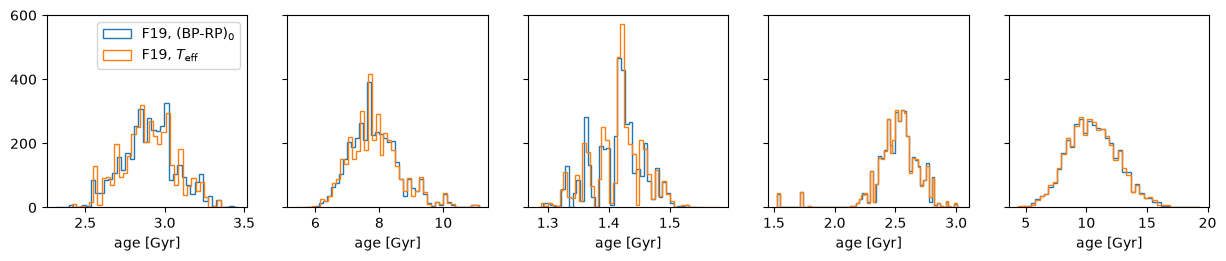

In [4]:
from dataclasses import replace
from decima.extinction import F19_TEFF, F19_TEFF_RANGE

law = decima.PolynomialLaw(F19_TEFF, x="teff", x_range=F19_TEFF_RANGE)
summary_t, samples_t, _ = decima.infer("../tests/data/reference_stars.ecsv", columns, replace(cfg, extinction=law))

names = decima.quantity_names(cfg)
fig, axes = plt.subplots(1, len(summary), figsize=(3 * len(summary), 2.5), sharey=True)
for i, ax in enumerate(axes):
    ax.hist(samples[i, :, names.index("age")], bins='fd', histtype="step", label="F19, (BP-RP)$_0$")
    ax.hist(samples_t[i, :, names.index("age")], bins='fd', histtype="step", label="F19, $T_\\mathrm{eff}$")
    ax.set_xlabel("age [Gyr]")
axes[0].legend()
plt.show()